## Pretrained BLIP VQA baseline (VizWiz)

**Research question:** Does a pretrained vision-language model outperform our question-only TF-IDF baseline, particularly on answerable questions?

We evaluate **`Salesforce/blip-vqa-base` without any VizWiz fine-tuning**. We first inspect a few predictions, then save inference outputs incrementally and evaluate on the official VizWiz **validation** split. The test split is not used.

**Environment:** VS Code + Colab GPU (T4 is sufficient). **Data:** `val.json` and the corresponding `VizWiz_val_*.jpg` images must be accessible to the *remote* Python runtime; a VS Code local folder is not automatically mounted there. **Results:** save to persistent storage (Google Drive if using Colab).

References: [BLIP model card](https://huggingface.co/Salesforce/blip-vqa-base) · [VizWiz task/evaluation](https://vizwiz.org/tasks-and-datasets/vqa/).


## Setup and configuration

Run the install cell **only if imports fail**. The model card recommends direct loading (rather than the removed Transformers v5 VQA pipeline). A kernel restart may be necessary after installing packages.


In [1]:
# Uncomment and run only if needed, then restart kernel if prompted.
# %pip install -U "transformers>=4.46" accelerate pillow pandas matplotlib tqdm


In [3]:
import json, random, re, time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from transformers import AutoProcessor, AutoModelForVisualQuestionAnswering
import transformers

SEED = 740
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_ID = "Salesforce/blip-vqa-base"
BATCH_SIZE = 4  # start conservative on T4; increase after testing
SAVE_EVERY = 16  # persist predictions after this many images
MAX_NEW_TOKENS = 20

print("PyTorch:", torch.__version__, "Transformers:", transformers.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: Running BLIP on CPU will be slow.")


PyTorch: 2.14.1+cu130 Transformers: 5.22.1
Device: cuda
GPU: Tesla T4


### Choose dataset and output locations

**Recommended for Colab:** Upload `data/Annotations/val.json` and the extracted `data/val/` folder to Google Drive, e.g. `MyDrive/VQA-Project/data/`. In a **browser Colab notebook**, you can mount Drive with the next cell. If VS Code's Colab extension cannot complete Drive authentication, open the notebook in the Colab browser for this step; alternatively use another persistent mounted storage location.

**Local VS Code:** The code also detects the project root, but local CPU inference may be slow. Set `DATA_ROOT` and `OUTPUT_ROOT` manually if your directories differ. **Do not write to `/content/` only** if you need results to survive Colab resets.


In [4]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
# If your Google Drive path differs, edit this one line.
DRIVE_PROJECT = Path("/content/drive/MyDrive/VQA-Project")

cwd = Path.cwd()
local_root = next((p for p in (cwd, cwd.parent)
                   if (p / "data" / "Annotations" / "val.json").exists()), None)

if (DRIVE_PROJECT / "data" / "Annotations" / "val.json").exists():
    PROJECT_ROOT = DRIVE_PROJECT
elif local_root is not None:
    PROJECT_ROOT = local_root
else:
    raise FileNotFoundError(
        "Cannot find data/Annotations/val.json in the current runtime. "
        "Upload/mount the validation data on the Colab machine or set PROJECT_ROOT."
    )

DATA_ROOT = PROJECT_ROOT / "data"
ANNOTATION_PATH = DATA_ROOT / "Annotations" / "val.json"
IMAGE_DIR = DATA_ROOT / "val"
OUTPUT_ROOT = PROJECT_ROOT / "results" / "blip_pretrained"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("Annotations:", ANNOTATION_PATH)
print("Images:", IMAGE_DIR)
print("Output (persistent location recommended):", OUTPUT_ROOT)
print("Image directory exists:", IMAGE_DIR.is_dir())


Annotations: /content/drive/MyDrive/VQA-Project/data/Annotations/val.json
Images: /content/drive/MyDrive/VQA-Project/data/val
Output (persistent location recommended): /content/drive/MyDrive/VQA-Project/results/blip_pretrained
Image directory exists: True


## B — Load validation annotations

We keep the same validation split used for the question-only baseline. No target labels are given to BLIP during inference.


In [6]:
with ANNOTATION_PATH.open(encoding="utf-8") as f:
    val_df = pd.DataFrame(json.load(f))

print("Validation examples:", len(val_df))
print("Answerability counts:", val_df["answerable"].value_counts().to_dict())
print("Example question:", val_df.iloc[0]["question"])

missing = [name for name in val_df["image"] if not (IMAGE_DIR / name).is_file()]
print("Missing validation images:", len(missing))
if missing:
    print("Examples:", missing[:5])
    raise FileNotFoundError("Validation images are not available to the running Python kernel.")


Validation examples: 4319
Answerability counts: {1: 2934, 0: 1385}
Example question: Ok. There is another picture I hope it is a better one.
Missing validation images: 0


The validation distribution is:
| Label        | Examples | Percentage |
|--------------|----------|------------|
| Answerable   | 2,934    | 67.93%     |
| Unanswerable | 1,385    | 32.07%     |
| **Total**    | **4,319**| **100%**   |

The Hugging Face HF_TOKEN warning is not a problem here. The model is publicly accessible and downloaded successfully. You don't need to configure a token for this experiment.

## C — Load pretrained BLIP (no fine-tuning)

Use `model.eval()` and inference mode; gradients and optimizer steps are unnecessary. Keep generation settings fixed for all experiments.


In [7]:
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForVisualQuestionAnswering.from_pretrained(MODEL_ID).to(DEVICE)
model.eval()

print("Loaded:", MODEL_ID)
print("Trainable weights are unchanged; inference only.")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


preprocessor_config.json:   0%|          | 0.00/445 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.54GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/788 [00:00<?, ?it/s]

Loaded: Salesforce/blip-vqa-base
Trainable weights are unchanged; inference only.


In [8]:
@torch.inference_mode()
def predict_batch(rows):
    images = []
    for name in rows["image"]:
        with Image.open(IMAGE_DIR / name) as img:
            images.append(img.convert("RGB"))

    encoded = processor(
        images=images,
        text=rows["question"].astype(str).tolist(),
        return_tensors="pt",
        padding=True,
    ).to(DEVICE)

    tokens = model.generate(**encoded, max_new_tokens=MAX_NEW_TOKENS,
                            num_beams=3, do_sample=False)
    return [s.strip() for s in processor.batch_decode(tokens, skip_special_tokens=True)]


## D — Inspect a small, reproducible sample first

These examples are selected only for **qualitative inspection**, not model selection. We will not change generation settings based on individual examples.


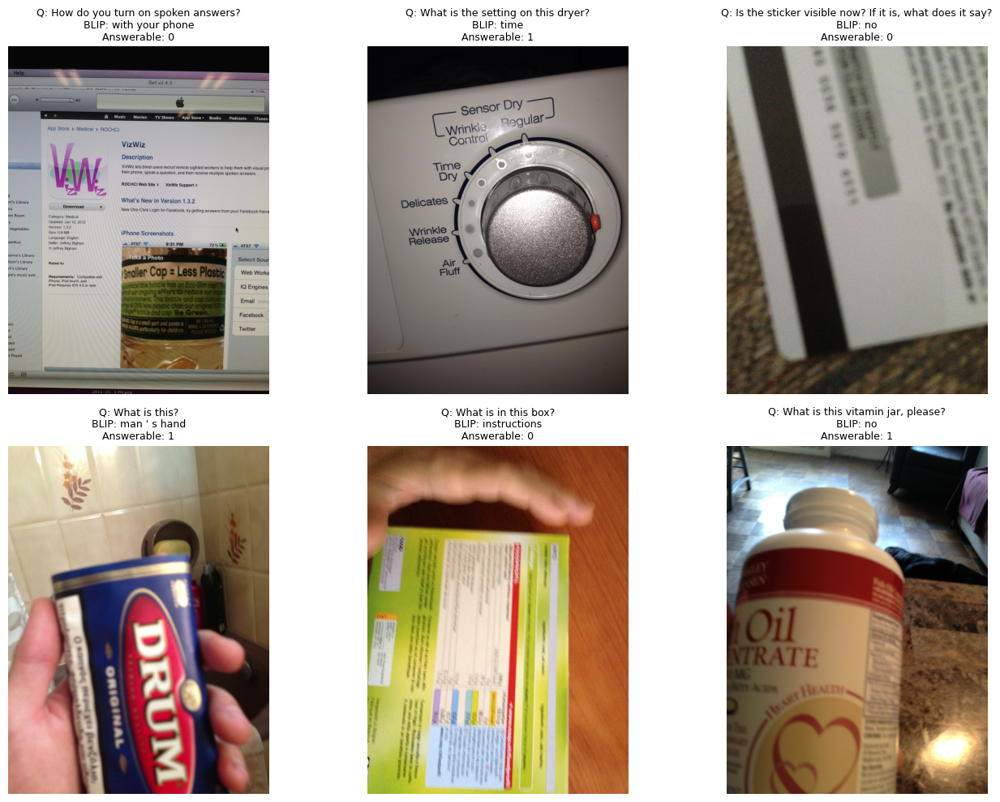

In [9]:
preview_df = val_df.sample(n=6, random_state=SEED).reset_index(drop=True)
preview_predictions = predict_batch(preview_df)

fig, axes = plt.subplots(2, 3, figsize=(14, 10))
for ax, (_, row), pred in zip(axes.flat, preview_df.iterrows(), preview_predictions):
    with Image.open(IMAGE_DIR / row["image"]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"Q: {row['question'][:65]}\nBLIP: {pred}\nAnswerable: {row['answerable']}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


These examples are especially useful because they show where a pretrained model struggles before any VizWiz fine-tuning.

| Question | BLIP prediction | Observation |
|---|---|---|
| How do you turn on spoken answers? | with your phone | Incorrect and not grounded in the screenshot |
| What is the setting on this dryer? | time | Related to the dial, but not the specific selected setting |
| Is the sticker visible now? | no | Plausible response, but the image is blurry |
| What is this? | man's hand | Focuses on a visible hand rather than the product |
| What is in this box? | instructions | Appears to infer contents from packaging rather than observing them |
| What is this vitamin jar? | no | Answer format doesn't match the identification question |

Three interesting findings
1. BLIP sometimes focuses on the wrong object.
In the DRUM container example, the model predicts "man's hand" instead of identifying the container.
This suggests difficulty identifying which visual object is relevant to the user's question.

2. BLIP sometimes produces answers that aren't sufficiently grounded in the image.
The box example illustrates this. The question asks about the contents, but the image shows the packaging rather than its contents.
The model predicts "instructions" despite insufficient visible evidence to confirm that answer.

3. BLIP doesn't consistently recognize unanswerable questions.
None of these six predictions is "unanswerable".
That is particularly interesting given that our question-only baseline predicted "unanswerable" for 85.7% of validation questions.
However, six samples are far too few to estimate BLIP's actual answerability performance.


These observations suggest that pretrained BLIP may have the opposite weakness from our question-only classifier:
- The question-only classifier overpredicts "unanswerable".
- Pretrained BLIP appears willing to generate specific answers even when the relevant information isn't visible.
This gives us a useful hypothesis for fine-tuning:
Adapting BLIP to VizWiz may improve both visual answer relevance and the model's ability to recognize unanswerable questions.

We'll test this rather than assume it's true.

## E — Run validation inference with incremental saving and resume

**Critical for Colab:** Prediction outputs are appended to a JSONL file on persistent storage every `SAVE_EVERY` examples. Re-running after a disconnected runtime skips all images already saved. Model weights must be reloaded after a full runtime reset, but completed inference **does not** need to be repeated.

- First run: set `EVAL_LIMIT = 200` for an inexpensive pilot.
- Final comparison: set `EVAL_LIMIT = None` and run all 4,319 validation examples. The same JSONL file can be resumed; all pilot records are retained.
- Keep `MODEL_ID`, generation settings, and the evaluation split unchanged when resuming. If you change them, use a new `PREDICTIONS_PATH`.


In [10]:
EVAL_LIMIT = 200  # change to None for all validation examples

# The validation order is fixed; this enables seamless expansion from 200 to all.
eval_df = val_df if EVAL_LIMIT is None else val_df.head(EVAL_LIMIT)
PREDICTIONS_PATH = OUTPUT_ROOT / "predictions_blip_vqa_base.jsonl"

saved = {}
if PREDICTIONS_PATH.exists():
    with PREDICTIONS_PATH.open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                record = json.loads(line)
                saved[record["image"]] = record["prediction"]
print(f"Loaded {len(saved)} previously saved predictions")

pending = eval_df[~eval_df["image"].isin(saved)].reset_index(drop=True)
print(f"Target: {len(eval_df)}, already finished: {len(eval_df)-len(pending)}, remaining: {len(pending)}")

start = time.perf_counter()
buffer = []
with PREDICTIONS_PATH.open("a", encoding="utf-8") as out:
    for start_idx in tqdm(range(0, len(pending), BATCH_SIZE), desc="BLIP inference"):
        rows = pending.iloc[start_idx:start_idx + BATCH_SIZE]
        answers = predict_batch(rows)
        for image_name, answer in zip(rows["image"], answers):
            record = {"image": image_name, "prediction": answer}
            buffer.append(record)
            saved[image_name] = answer
        if len(buffer) >= SAVE_EVERY:
            for record in buffer:
                out.write(json.dumps(record, ensure_ascii=False) + "\n")
            out.flush()
            buffer.clear()
    for record in buffer:
        out.write(json.dumps(record, ensure_ascii=False) + "\n")
    out.flush()

print("Saved predictions:", PREDICTIONS_PATH)
print("Inference time this run (s):", round(time.perf_counter() - start, 1))


Loaded 4319 previously saved predictions
Target: 200, already finished: 200, remaining: 0


BLIP inference: 0it [00:00, ?it/s]

Saved predictions: /content/drive/MyDrive/VQA-Project/results/blip_pretrained/predictions_blip_vqa_base.jsonl
Inference time this run (s): 0.0


## F — Calculate the **same preliminary VQA-style metric** as the question-only notebook

For direct comparability, this reproduces the earlier notebook's simple case/whitespace normalization and ten-annotator leave-one-out scoring. **This is not yet the official VizWiz benchmark evaluator**, which applies additional answer normalization. We will run the official evaluation for the final report.


In [11]:
def normalize_simple(text):
    return re.sub(r"\s+", " ", str(text).strip().lower())


def majority_answer(row):
    return Counter(normalize_simple(a["answer"]) for a in row["answers"]).most_common(1)[0][0]


def vqa_style_score(prediction, answers):
    p = normalize_simple(prediction)
    refs = [normalize_simple(a["answer"]) for a in answers]
    return float(np.mean([
        min(sum(p == ref for j, ref in enumerate(refs) if j != i) / 3.0, 1.0)
        for i in range(len(refs))
    ]))

# Reload disk predictions in case this is a fresh kernel session.
with PREDICTIONS_PATH.open(encoding="utf-8") as f:
    saved = {r["image"]: r["prediction"] for line in f if line.strip()
             for r in [json.loads(line)]}

scored_df = eval_df[eval_df["image"].isin(saved)].copy()
scored_df["prediction"] = scored_df["image"].map(saved)
scored_df["majority_answer"] = scored_df.apply(majority_answer, axis=1)
scored_df["vqa_style_score"] = [vqa_style_score(pred, refs)
    for pred, refs in zip(scored_df["prediction"], scored_df["answers"])]

answerable_mask = scored_df["answerable"].eq(1)
metrics = {
    "model": MODEL_ID,
    "n_evaluated": len(scored_df),
    "overall_vqa_style": scored_df["vqa_style_score"].mean(),
    "answerable_vqa_style": scored_df.loc[answerable_mask, "vqa_style_score"].mean(),
    "unanswerable_vqa_style": scored_df.loc[~answerable_mask, "vqa_style_score"].mean(),
    "exact_majority_accuracy": (scored_df["prediction"].map(normalize_simple)
        == scored_df["majority_answer"]).mean(),
    "predicted_unanswerable_rate": scored_df["prediction"].map(normalize_simple).eq("unanswerable").mean(),
    "unanswerable_on_answerable_rate": scored_df.loc[answerable_mask, "prediction"]
        .map(normalize_simple).eq("unanswerable").mean(),
}
print(pd.Series(metrics).to_string())
print("NOTE: Pilot results use only a subset unless EVAL_LIMIT=None.")


model                              Salesforce/blip-vqa-base
n_evaluated                                             200
overall_vqa_style                                    0.1255
answerable_vqa_style                               0.154286
unanswerable_vqa_style                             0.093684
exact_majority_accuracy                                0.06
predicted_unanswerable_rate                             0.0
unanswerable_on_answerable_rate                         0.0
NOTE: Pilot results use only a subset unless EVAL_LIMIT=None.


## G — Save results and review errors

Keep the underlying question/image identifiers so we can compare **the same examples** with the TF-IDF baseline and later fine-tuned BLIP. If comparing against the earlier *full-validation* TF-IDF metrics, first run BLIP on the **full validation** split as well.


In [12]:
scored_df[["image", "question", "answerable", "prediction", "majority_answer",
           "vqa_style_score"]].to_csv(OUTPUT_ROOT / "validation_predictions.csv", index=False)
(OUTPUT_ROOT / "validation_metrics.json").write_text(
    json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8")

print("Lowest-scoring examples:")
display(scored_df.nsmallest(12, "vqa_style_score")[[
    "question", "prediction", "majority_answer", "answerable", "vqa_style_score"
]])


Lowest-scoring examples:


,question,prediction,majority_answer,answerable,vqa_style_score
0,Ok. There is another picture I hope it is a be...,i don ' t know,unanswerable,0,0.0
1,Can you tell me what this medicine is please?,yes,night time,1,0.0
2,What is the title of this book?,dog days,dog years,1,0.0
3,Which one is the blue one?,left,right,1,0.0
4,What does the arrow say?,7 seconds,unanswerable,0,0.0
5,What the screen says? Thank you.,no,unanswerable,1,0.0
6,What is seen on the laptop screen? What is see...,reflection,unanswerable,0,0.0
8,Is this shampoo or conditioner?,yes,unanswerable,0,0.0
9,Can you describe for me what's going on outsid...,school bus,nothing,1,0.0
10,What about the signery.,no idea,unanswerable,0,0.0


## H — Interpretation

- **Overall:** Compare BLIP and TF-IDF VQA-style accuracy using the **same complete validation set and normalization**.

The results are interesting because BLIP performs poorly overall, but its failure pattern is very different from the TF-IDF classifier.

1. Pretrained BLIP results — 200 examples
Validation pilot
200 / 4,319

Overall VQA-style accuracy
12.55%

Answerable-only accuracy
15.43%

Unanswerable-only accuracy
9.37%

Exact majority accuracy
6.00%

The model is not yet adapted to VizWiz, so these numbers represent zero-shot transfer performance from its pretrained VQA capabilities.
Why is BLIP performing so poorly?
Your error examples suggest three major problems:
1. Incorrect visual grounding: It predicts "left" when the reference answer is "right", or "dog days" instead of "dog years".
2. Inappropriate answer formats: It responds "yes" to identification questions, such as asking which medicine or shampoo is shown.
3. Poor handling of unanswerable questions: It generates guesses or natural-language uncertainty rather than the dataset's exact "unanswerable" label.
These observations support our hypothesis that domain adaptation may be particularly valuable for VizWiz.
2. An important issue in your evaluation
Your notebook reports:
predicted_unanswerable_rate: 0.0
unanswerable_on_answerable_rate: 0.0


But look at two of your predictions:
Question	BLIP prediction
Another picture, hopefully better	i don ' t know
What about the signery?	no idea

These are expressions of uncertainty, but your evaluation only counts the exact string "unanswerable".

Therefore, 0% doesn't mean BLIP never indicates uncertainty. It means BLIP never generated that particular label in these 200 examples.

We should preserve this metric for reproducibility, but add a separate diagnostic for natural-language abstentions.

### Discussion of Research Questions — Preliminary Evaluation

**Answerable questions:** Pretrained BLIP achieved 15.43% VQA-style accuracy on the initial 200 validation examples. The question-only TF-IDF baseline achieved 32.13% on the full validation set. Because these evaluations cover different sets of examples, we cannot yet determine whether visual information improves performance.

**Unanswerable questions:** BLIP frequently generated specific answers even when visual evidence appeared insufficient. Examples included inappropriate yes/no responses and guesses about information not visible in the image. This suggests difficulty handling unanswerable questions, although the prevalence of unsupported answers has not yet been quantified.

**Unanswerable predictions:** BLIP did not generate the exact label `"unanswerable"` in the 200-example pilot. However, responses such as `"no idea"` and `"i don't know"` indicate that the model occasionally expresses uncertainty using alternative wording. The exact-label prediction rate therefore does not capture every form of abstention.

**Qualitative failures:** Initial examples revealed difficulties with fine-grained visual grounding, text recognition, image quality, and answer-format consistency. Additional error categorization is needed to distinguish these failure modes systematically.

**Limitations:** The BLIP checkpoint was previously trained for generic visual question answering. This experiment therefore measures transfer without additional VizWiz fine-tuning, rather than performance from random initialization or verified strict zero-shot dataset separation. Results are preliminary because they cover 200 validation examples and use simplified VQA-style answer normalization.

**Next steps:** Complete full-validation inference, evaluate pretrained BLIP and the question-only baseline on identical examples, and then investigate whether VizWiz-specific fine-tuning improves performance under a controlled experimental setup.


Our next step is to complete the pretrained BLIP evaluation on all 4,319 VizWiz validation examples, then analyze the results before fine-tuning.

## I — Full Validation Evaluation

We evaluate the pretrained BLIP model on the complete VizWiz
validation dataset (4,319 examples), without additional fine-tuning.

The evaluation includes overall and answerability-specific VQA-style
accuracy, exact majority-answer accuracy, uncertainty analysis,
and qualitative error inspection.

The original 200-example pilot results are preserved separately.

Load saved predictions and calculate evaluation metrics

In [13]:

# ==========================================================
# FULL VALIDATION INFERENCE — RESUME FROM SAVED PREDICTIONS
# ==========================================================

import json
import time
from tqdm.auto import tqdm

# Use all validation examples without changing EVAL_LIMIT
full_inference_df = val_df.copy()

# Same prediction file used for the 200-example pilot
FULL_PREDICTIONS_PATH = (
    OUTPUT_ROOT / "predictions_blip_vqa_base.jsonl"
)

# Load previously completed predictions
saved_full = {}

if FULL_PREDICTIONS_PATH.exists():
    with FULL_PREDICTIONS_PATH.open("r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                record = json.loads(line)
                saved_full[record["image"]] = record["prediction"]

# Find only images that still need predictions
pending_full = full_inference_df[
    ~full_inference_df["image"].isin(saved_full)
].reset_index(drop=True)

print("Total validation examples:", len(full_inference_df))
print(
    "Previously completed:",
    len(full_inference_df) - len(pending_full)
)
print("Remaining:", len(pending_full))

# Keep the same inference configuration as the pilot
model.eval()

start_time = time.perf_counter()
buffer = []

with FULL_PREDICTIONS_PATH.open("a", encoding="utf-8") as out:

    for start_idx in tqdm(
        range(0, len(pending_full), BATCH_SIZE),
        desc="Full BLIP validation"
    ):

        batch = pending_full.iloc[
            start_idx:start_idx + BATCH_SIZE
        ]

        # Reuse the original BLIP inference function
        predictions = predict_batch(batch)

        for image_name, prediction in zip(
            batch["image"], predictions
        ):
            buffer.append({
                "image": image_name,
                "prediction": prediction
            })

        # Save progress periodically
        if len(buffer) >= SAVE_EVERY:
            for record in buffer:
                out.write(
                    json.dumps(record, ensure_ascii=False) + "\n"
                )

            out.flush()
            buffer.clear()

    # Save any remaining predictions
    for record in buffer:
        out.write(
            json.dumps(record, ensure_ascii=False) + "\n"
        )

    out.flush()

elapsed = time.perf_counter() - start_time

print("\nFull inference completed.")
print(f"Time this run: {elapsed:.1f} seconds")
print("Predictions saved to:", FULL_PREDICTIONS_PATH)


Total validation examples: 4319
Previously completed: 4319
Remaining: 0


Full BLIP validation: 0it [00:00, ?it/s]


Full inference completed.
Time this run: 0.0 seconds
Predictions saved to: /content/drive/MyDrive/VQA-Project/results/blip_pretrained/predictions_blip_vqa_base.jsonl


Verify saved predictions

In [14]:

# Verify full-validation prediction coverage

saved_full = {}

with FULL_PREDICTIONS_PATH.open("r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            record = json.loads(line)
            saved_full[record["image"]] = record["prediction"]

expected_images = set(val_df["image"])
completed_images = set(saved_full)

missing_images = expected_images - completed_images

print("Expected examples:", len(expected_images))
print("Saved unique predictions:", len(completed_images))
print("Missing predictions:", len(missing_images))

if missing_images:
    print("First missing images:", sorted(missing_images)[:5])
else:
    print("Full validation inference is complete!")


Expected examples: 4319
Saved unique predictions: 4319
Missing predictions: 0
Full validation inference is complete!


Inspect the prediction and ground-truth files

In [15]:
import json
from pathlib import Path

BASE = Path("/content/drive/MyDrive/VQA-Project")

pred_path = BASE / "results/blip_pretrained/predictions_blip_vqa_base.jsonl"

with open(pred_path, "r") as f:
    predictions = [json.loads(line) for line in f if line.strip()]

print("Total predictions:", len(predictions))
print("\nFirst 3 predictions:")

for p in predictions[:3]:
    print(json.dumps(p, indent=2))

Total predictions: 4319

First 3 predictions:
{
  "image": "VizWiz_val_00000000.jpg",
  "prediction": "i don ' t know"
}
{
  "image": "VizWiz_val_00000001.jpg",
  "prediction": "yes"
}
{
  "image": "VizWiz_val_00000002.jpg",
  "prediction": "dog days"
}


In [20]:

import json
import re
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd

BASE = Path("/content/drive/MyDrive/VQA-Project")
OUTPUT_ROOT = BASE / "results" / "blip_pretrained"

VAL_PATH = BASE / "data" / "Annotations" / "val.json"
PRED_PATH = OUTPUT_ROOT / "predictions_blip_vqa_base.jsonl"

# Load validation ground truth
with VAL_PATH.open("r", encoding="utf-8") as f:
    val_df = pd.DataFrame(json.load(f))

# Load all saved BLIP predictions
with PRED_PATH.open("r", encoding="utf-8") as f:
    prediction_records = [
        json.loads(line)
        for line in f if line.strip()
    ]

pred_df = pd.DataFrame(prediction_records)

# Verify prediction integrity
assert val_df["image"].is_unique
assert pred_df["image"].is_unique, "Duplicate predictions found!"
assert len(val_df) == 4319
assert set(val_df["image"]) == set(pred_df["image"])

# Match by filename, not row position
full_df = val_df.merge(
    pred_df[["image", "prediction"]],
    on="image",
    how="left",
    validate="one_to_one"
)

assert full_df["prediction"].notna().all()

print("Validation examples:", len(val_df))
print("Saved predictions:", len(pred_df))
print("Matched examples:", len(full_df))
print("Missing predictions:", full_df["prediction"].isna().sum())
print("Answerability:", full_df["answerable"].value_counts().to_dict())

display(full_df[["image", "question", "prediction", "answerable"]].head())


Validation examples: 4319
Saved predictions: 4319
Matched examples: 4319
Missing predictions: 0
Answerability: {1: 2934, 0: 1385}


,image,question,prediction,answerable
0,VizWiz_val_00000000.jpg,Ok. There is another picture I hope it is a be...,i don ' t know,0
1,VizWiz_val_00000001.jpg,Can you tell me what this medicine is please?,yes,1
2,VizWiz_val_00000002.jpg,What is the title of this book?,dog days,1
3,VizWiz_val_00000003.jpg,Which one is the blue one?,left,1
4,VizWiz_val_00000004.jpg,What does the arrow say?,7 seconds,0


## Calculating full validation accuracy

In [21]:

def normalize_simple(text):
    return re.sub(r"\s+", " ", str(text).strip().lower())


def majority_answer(answers):
    normalized = [
        normalize_simple(a["answer"])
        for a in answers
    ]
    return Counter(normalized).most_common(1)[0][0]


def vqa_style_score(prediction, answers):
    p = normalize_simple(prediction)
    refs = [
        normalize_simple(a["answer"])
        for a in answers
    ]

    # Leave-one-annotator-out VQA scoring
    scores = [
        min(
            sum(
                p == ref
                for j, ref in enumerate(refs)
                if j != i
            ) / 3.0,
            1.0
        )
        for i in range(len(refs))
    ]

    return float(np.mean(scores))


full_df["majority_answer"] = full_df["answers"].apply(
    majority_answer
)

full_df["vqa_style_score"] = [
    vqa_style_score(pred, refs)
    for pred, refs in zip(
        full_df["prediction"],
        full_df["answers"]
    )
]

full_df["normalized_prediction"] = (
    full_df["prediction"].map(normalize_simple)
)

answerable_mask = full_df["answerable"].eq(1)

full_metrics = {
    "model": "Salesforce/blip-vqa-base",
    "n_evaluated": len(full_df),
    "overall_vqa_style": float(
        full_df["vqa_style_score"].mean()
    ),
    "answerable_vqa_style": float(
        full_df.loc[
            answerable_mask, "vqa_style_score"
        ].mean()
    ),
    "unanswerable_vqa_style": float(
        full_df.loc[
            ~answerable_mask, "vqa_style_score"
        ].mean()
    ),
    "exact_majority_accuracy": float(
        (
            full_df["normalized_prediction"]
            == full_df["majority_answer"]
        ).mean()
    ),
    "predicted_unanswerable_rate": float(
        full_df["normalized_prediction"]
        .eq("unanswerable").mean()
    ),
    "unanswerable_on_answerable_rate": float(
        full_df.loc[
            answerable_mask, "normalized_prediction"
        ].eq("unanswerable").mean()
    )
}

print("FULL VALIDATION RESULTS")
print("=" * 45)

for key, value in full_metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.2%}")
    else:
        print(f"{key}: {value}")


FULL VALIDATION RESULTS
model: Salesforce/blip-vqa-base
n_evaluated: 4319
overall_vqa_style: 19.94%
answerable_vqa_style: 25.62%
unanswerable_vqa_style: 7.91%
exact_majority_accuracy: 13.94%
predicted_unanswerable_rate: 0.00%
unanswerable_on_answerable_rate: 0.00%


## Analyze how BLIP handles unanswerable questions

In [22]:

# Conservative set of recognizable uncertainty responses.
# This is a diagnostic, not the official VQA metric.
ABSTENTION_PHRASES = {
    "unanswerable",
    "unknown",
    "unsure",
    "not sure",
    "i don't know",
    "i do not know",
    "don't know",
    "do not know",
    "no idea",
    "can't tell",
    "cannot tell",
    "can't see",
    "cannot see"
}

def normalize_abstention(text):
    text = normalize_simple(text)
    text = re.sub(r"\s*'\s*", "'", text)
    text = re.sub(r"[.!?,]+$", "", text)
    return text.strip()


full_df["is_abstention"] = (
    full_df["prediction"]
    .map(normalize_abstention)
    .isin(ABSTENTION_PHRASES)
)

# Ground truth uses the dataset's answerable label
full_df["is_unanswerable"] = (
    full_df["answerable"].eq(0)
)

tp = int((
    full_df["is_abstention"]
    & full_df["is_unanswerable"]
).sum())

fp = int((
    full_df["is_abstention"]
    & ~full_df["is_unanswerable"]
).sum())

fn = int((
    ~full_df["is_abstention"]
    & full_df["is_unanswerable"]
).sum())

tn = int((
    ~full_df["is_abstention"]
    & ~full_df["is_unanswerable"]
).sum())

precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0.0
)

print("UNANSWERABLE DETECTION — HEURISTIC")
print("=" * 45)
print(f"True positives:  {tp}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True negatives:  {tn}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")
print(f"F1-score:  {f1:.2%}")
print(f"Abstention rate: {full_df['is_abstention'].mean():.2%}")

print("\nMost common BLIP predictions:")
display(
    full_df["normalized_prediction"]
    .value_counts()
    .head(20)
    .rename_axis("prediction")
    .reset_index(name="count")
)

print("\nExamples of recognized abstentions:")
display(
    full_df.loc[
        full_df["is_abstention"],
        ["question", "prediction", "answerable"]
    ].head(15)
)


UNANSWERABLE DETECTION — HEURISTIC
True positives:  131
False positives: 88
False negatives: 1254
True negatives:  2846
Precision: 59.82%
Recall:    9.46%
F1-score:  16.33%
Abstention rate: 5.07%

Most common BLIP predictions:


,prediction,count
0,yes,580
1,no,508
2,white,78
3,no idea,74
4,i don ' t know,72
5,black,55
6,blue,51
7,0,46
8,cell phone,45
9,book,43



Examples of recognized abstentions:


,question,prediction,answerable
0,Ok. There is another picture I hope it is a be...,i don ' t know,0
10,What about the signery.,no idea,0
13,Who is this mail for?,no idea,0
42,What does this fortune cookie say?,no idea,0
54,What's the name of the drink?,no idea,1
70,"About this one, thank you.",i don ' t know,0
80,What is this show?,no idea,1
82,Is my computer performing a disc check? For ex...,no idea,0
85,please explain what is on this piece of paper,no idea,1
99,Alright. If you could tell what the screen say...,i don ' t know,1


# Pretrained BLIP VQA — Validation Results and Observations

## 1. Objective

Evaluate the performance of the pretrained `Salesforce/blip-vqa-base` model on the VizWiz validation dataset, focusing on:

- Visual Question Answering (VQA) accuracy.
- Performance differences between answerable and unanswerable questions.
- The model's ability to recognize insufficient visual information.
- Common prediction patterns and failure cases.

The purpose of this experiment is to establish a baseline before fine-tuning BLIP on the VizWiz training dataset.

## 2. Dataset and Experimental Setup

| Component | Description |
|---|---|
| Dataset | VizWiz VQA |
| Split | Validation |
| Model | `Salesforce/blip-vqa-base` |
| Total examples | 4,319 |
| Answerable examples | 2,934 (67.93%) |
| Unanswerable examples | 1,385 (32.07%) |
| Human annotations | 10 answers per question |
| Evaluation | VQA-style accuracy, exact majority-match accuracy, heuristic abstention detection |

Pretrained BLIP inference was completed for all 4,319 validation examples. Predictions were saved to a JSONL file, and every prediction was successfully matched with its corresponding validation annotation using the image filename.

**Validation integrity checks:**

- Total predictions: 4,319
- Unique matched predictions: 4,319
- Missing predictions: 0

No examples were missing from the evaluation.

## 3. Quantitative Evaluation Results

### 3.1 VQA Accuracy

| Metric | Result |
|---|---:|
| Overall VQA-style accuracy | 19.94% |
| Answerable VQA-style accuracy | 25.62% |
| Unanswerable VQA-style accuracy | 7.91% |
| Exact majority-answer accuracy | 13.94% |

**Observations:**

1. BLIP achieved an overall VQA-style accuracy of 19.94% across the complete validation set.
2. Performance was considerably better on answerable questions (25.62%) than on unanswerable questions (7.91%).
3. The difference indicates that recognizing insufficient visual information is a major weakness of the pretrained model.
4. The low exact majority-answer accuracy also suggests difficulty matching the specific answers provided by human annotators.

**Evaluation note:** These results use a leave-one-annotator-out VQA-style scoring function with simple text normalization. They should be treated as preliminary baseline metrics until verified using the official VizWiz evaluation implementation.

### 3.2 Unanswerable Question Detection

An additional heuristic evaluation was performed to detect whether BLIP expressed uncertainty through responses such as:

- `unanswerable`
- `no idea`
- `i don't know`
- `can't tell`
- `not sure`

| Metric | Result |
|---|---:|
| True positives | 131 |
| False positives | 88 |
| False negatives | 1,254 |
| True negatives | 2,846 |
| Precision | 59.82% |
| Recall | 9.46% |
| F1-score | 16.33% |
| Overall abstention rate | 5.07% |

**Observations:**

1. BLIP correctly expressed uncertainty for only 131 of the 1,385 unanswerable questions.
2. The model failed to abstain on 1,254 unanswerable examples.
3. Its recall of 9.46% indicates that the model rarely recognizes when it should avoid generating an answer.
4. Precision of 59.82% indicates that some abstentions occur even when the question is labelled answerable.
5. BLIP never generated the exact label `unanswerable`, despite occasionally producing natural-language uncertainty expressions.

**Interpretation:** Pretrained BLIP has a limited ability to express uncertainty, but its behaviour is not reliably aligned with the VizWiz answerability annotations.

These metrics are based on a manually defined list of uncertainty phrases and should be reported as heuristic results rather than official answerability classification scores.

## 4. Prediction Distribution

The most frequently generated BLIP answers were:

| Prediction | Count |
|---|---:|
| yes | 580 |
| no | 508 |
| white | 78 |
| no idea | 74 |
| i don't know | 72 |
| black | 55 |
| blue | 51 |
| 0 | 46 |
| cell phone | 45 |
| book | 43 |
| words | 41 |
| laptop | 38 |
| can't tell | 35 |
| phone | 32 |
| red | 30 |

**Observations:**

- `yes` and `no` were the most common predictions, accounting for 1,088 of the 4,319 examples (25.19%).
- BLIP frequently generated short answers involving colours and common objects.
- Uncertainty expressions appeared among the most frequent predictions but were considerably less common than direct answers.
- The model sometimes produced different expressions for similar meanings, such as `phone` and `cell phone`.
- The presence of short and frequently repeated answers may indicate a tendency toward common answer patterns. Further analysis is needed to determine whether these responses are grounded in the images.

## 5. Qualitative Observations

### 5.1 Failure to Recognize Unanswerable Questions

The most significant weakness observed was the low detection rate for unanswerable questions.

Although approximately 32% of the validation dataset was labelled unanswerable, BLIP expressed recognizable uncertainty in only 5.07% of its predictions overall.

This suggests that the model often attempts to generate an answer even when sufficient visual evidence may not be available.

### 5.2 Unnecessary Abstentions

Some answerable examples received uncertainty responses.

| Question | BLIP Prediction | Answerable |
|---|---|---:|
| What's the name of the drink? | no idea | 1 |
| What is this show? | no idea | 1 |
| What does this message say? | no idea | 1 |
| What does this say? Thank you. | not sure | 1 |

These examples show that BLIP sometimes expresses uncertainty even when the dataset considers a question answerable.

Without inspecting the corresponding images, we cannot determine whether these failures result from image quality, text recognition difficulties, or limitations in visual understanding.

### 5.3 Inconsistent Uncertainty Expressions

BLIP generated several variations of uncertainty, including:

- `no idea`
- `i don't know`
- `can't tell`
- `not sure`

These responses are semantically similar to abstaining, but they do not directly match the dataset label `unanswerable`.

This introduces a distinction between the model's natural-language behaviour and the exact-answer evaluation procedure.

A more comprehensive evaluation should distinguish between official VQA scoring and semantic uncertainty detection.

## 6. Key Findings

The pretrained BLIP experiment produced four main findings:

1. **Limited overall accuracy:** BLIP achieved 19.94% VQA-style accuracy without VizWiz-specific fine-tuning.
2. **Weak answerability detection:** Unanswerable-question performance was substantially worse than answerable-question performance.
3. **Low abstention recall:** BLIP missed approximately 90.54% of unanswerable examples under the heuristic detection procedure.
4. **Inconsistent uncertainty handling:** The model occasionally expressed uncertainty but did not consistently use a standard answerability label.

These findings establish the motivation for domain-specific fine-tuning and additional answerability-aware evaluation.

## 7. Limitations

- The current accuracy metric uses simple normalization rather than the official VizWiz evaluation implementation.
- The abstention detector relies on a manually defined phrase list and may miss other uncertainty expressions.
- The model has not yet been fine-tuned on VizWiz.
- Prediction-frequency analysis alone cannot demonstrate hallucination or visual grounding failures.
- Detailed image-level error categorization remains incomplete.
- Comparison against the question-only baseline has not yet been consolidated into the same evaluation report.

## 8. Next Steps

### Step 1 — Complete Qualitative Error Analysis

**Status:** In progress

- Categorize predictions into incorrect answers, partial agreement, unnecessary abstentions, and failures to abstain.
- Inspect representative images alongside questions, predictions, and human answers.
- Identify recurring visual challenges such as blur, poor framing, unreadable text, and missing objects.
- Distinguish visual perception failures from answerability failures.

**Deliverable:** An error-analysis table with representative examples and supporting observations.

### Step 2 — Compare Against the Question-Only Baseline

**Status:** Pending consolidated comparison

- Evaluate the question-only baseline and BLIP using the same validation examples.
- Apply identical text normalization and scoring procedures.
- Compare overall, answerable, and unanswerable accuracy.
- Determine whether adding visual information improves performance over language-only prediction.

**Deliverable:** Baseline comparison table and interpretation.

### Step 3 — Verify Official VizWiz Evaluation

**Status:** Pending

- Apply the official VizWiz/VQA answer normalization and scoring implementation.
- Recalculate the pretrained BLIP validation metrics.
- Keep official benchmark results separate from heuristic uncertainty metrics.

**Deliverable:** Verified baseline metrics suitable for the final report.

### Step 4 — Fine-Tune BLIP on VizWiz

**Status:** Not started

- Load the VizWiz training dataset.
- Prepare image–question–answer training examples.
- Establish a consistent target-answer selection strategy for questions with multiple human annotations.
- Evaluate whether the model should explicitly learn to predict `unanswerable`.
- Fine-tune pretrained BLIP using an appropriate GPU and monitor training and validation performance.
- Save trained model checkpoints and experiment configurations.

**Deliverable:** A VizWiz-fine-tuned BLIP model.

### Step 5 — Evaluate Fine-Tuned BLIP

**Status:** Pending

Compare the pretrained and fine-tuned models on the same validation split.

| Metric | Pretrained BLIP | Fine-Tuned BLIP |
|---|---:|---:|
| Overall VQA-style accuracy | 19.94% | TBD |
| Answerable accuracy | 25.62% | TBD |
| Unanswerable accuracy | 7.91% | TBD |
| Exact majority-answer accuracy | 13.94% | TBD |
| Heuristic abstention F1 | 16.33% | TBD |

The comparison will determine whether VizWiz-specific training improves both answer generation and uncertainty handling.

### Step 6 — Final Project Analysis

**Status:** Pending

- Compare the question-only, pretrained BLIP, and fine-tuned BLIP models.
- Present quantitative evaluation results and representative failure cases.
- Analyze the contribution of visual information.
- Discuss uncertainty, answerability, limitations, and possible improvements.
- Prepare the final technical report and presentation.

## 9. Current Conclusion

Pretrained BLIP demonstrates some ability to answer VizWiz questions but performs poorly on the validation dataset, particularly for unanswerable questions.

The model's tendency to provide direct answers despite insufficient visual information is an important limitation for accessibility-oriented VQA systems, where unreliable answers may mislead users.

These initial results motivate further error analysis and VizWiz-specific fine-tuning, with particular attention to robust answerability detection and reliable uncertainty handling.

Categorize prediction errors

In [ ]:

# import pandas as pd
# import numpy as np

# analysis_df = full_df.copy()

# def categorize_prediction(row):
#     answerable = int(row["answerable"]) == 1
#     abstained = bool(row["is_abstention"])
#     score = float(row["vqa_style_score"])

#     if not answerable:
#         return (
#             "Recognized uncertainty"
#             if abstained
#             else "Failed to abstain"
#         )

#     if abstained:
#         return "Unnecessary abstention"

#     if np.isclose(score, 0):
#         return "Incorrect answer"

#     if score < 1:
#         return "Partial agreement"

#     return "Full agreement"


# analysis_df["error_category"] = analysis_df.apply(
#     categorize_prediction,
#     axis=1
# )

# category_counts = (
#     analysis_df["error_category"]
#     .value_counts()
#     .rename_axis("category")
#     .reset_index(name="count")
# )

# category_counts["percentage"] = (
#     category_counts["count"] / len(analysis_df) * 100
# ).round(2)

# display(category_counts)

# assert category_counts["count"].sum() == 4319


,category,count,percentage
0,Incorrect answer,1889,43.74
1,Failed to abstain,1254,29.03
2,Full agreement,533,12.34
3,Partial agreement,424,9.82
4,Recognized uncertainty,131,3.03
5,Unnecessary abstention,88,2.04


Updated code — Separate VQA correctness from answerability detection
Instead of using one error_category column, we'll use two independent columns:
- vqa_category: How much credit BLIP receives for its answer.
- answerability_category: Whether BLIP appropriately expresses uncertainty.

In [27]:

import pandas as pd
import numpy as np

analysis_df = full_df.copy()

# --------------------------------------------
# 1. VQA correctness classification
# --------------------------------------------

def categorize_vqa(score):
    score = float(score)

    if np.isclose(score, 0):
        return "Zero VQA credit"
    elif np.isclose(score, 1):
        return "Full VQA credit"
    else:
        return "Partial VQA credit"


analysis_df["vqa_category"] = (
    analysis_df["vqa_style_score"]
    .apply(categorize_vqa)
)


# --------------------------------------------
# 2. Answerability detection classification
# --------------------------------------------

def categorize_answerability(row):
    is_answerable = int(row["answerable"]) == 1
    abstained = bool(row["is_abstention"])

    if not is_answerable and abstained:
        return "Correct abstention (heuristic)"

    elif not is_answerable and not abstained:
        return "Failed to abstain"

    elif is_answerable and abstained:
        return "Unnecessary abstention"

    else:
        return "Answered answerable question"


analysis_df["answerability_category"] = (
    analysis_df.apply(
        categorize_answerability,
        axis=1
    )
)


# --------------------------------------------
# 3. Display separate summary tables
# --------------------------------------------

print("VQA CORRECTNESS DISTRIBUTION")
print("=" * 45)

vqa_summary = (
    analysis_df["vqa_category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="count")
)

vqa_summary["percentage"] = (
    vqa_summary["count"] / len(analysis_df) * 100
).round(2)

display(vqa_summary)


print("\nANSWERABILITY DETECTION DISTRIBUTION")
print("=" * 45)

answerability_summary = (
    analysis_df["answerability_category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="count")
)

answerability_summary["percentage"] = (
    answerability_summary["count"]
    / len(analysis_df) * 100
).round(2)

display(answerability_summary)


# --------------------------------------------
# 4. Verify all examples are included
# --------------------------------------------

assert vqa_summary["count"].sum() == 4319
assert answerability_summary["count"].sum() == 4319

print("\nAll 4,319 examples categorized successfully.")


VQA CORRECTNESS DISTRIBUTION


,category,count,percentage
0,Zero VQA credit,3153,73.00
1,Partial VQA credit,615,14.24
2,Full VQA credit,551,12.76



ANSWERABILITY DETECTION DISTRIBUTION


,category,count,percentage
0,Answered answerable question,2846,65.89
1,Failed to abstain,1254,29.03
2,Correct abstention (heuristic),131,3.03
3,Unnecessary abstention,88,2.04



All 4,319 examples categorized successfully.


Visualize the error distribution

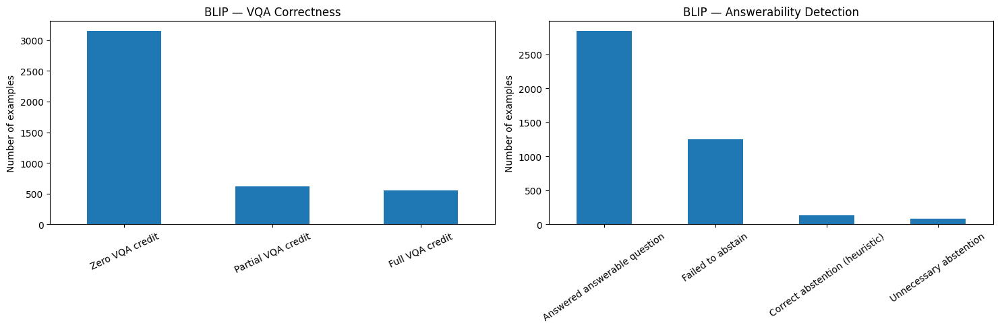

In [28]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# VQA correctness
vqa_counts = analysis_df["vqa_category"].value_counts()
vqa_counts.plot(kind="bar", ax=axes[0])

axes[0].set_title("BLIP — VQA Correctness")
axes[0].set_ylabel("Number of examples")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=25)

# Answerability detection
answerability_counts = (
    analysis_df["answerability_category"].value_counts()
)
answerability_counts.plot(kind="bar", ax=axes[1])

axes[1].set_title("BLIP — Answerability Detection")
axes[1].set_ylabel("Number of examples")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


## Inspect actual images and BLIP predictions
This is the most important part of qualitative analysis. We need to examine the images, not just the text, to understand why BLIP makes mistakes.

Image: VizWiz_val_00004316.jpg
Question: I need to buy this battery for my cordless phone, can you see the model and the name?
BLIP: no
Majority: unanswerable
Human answers: [('unanswerable', 7), ('no', 3)]
Answerable: 0
VQA score: 0.9
VQA category: Partial VQA credit
Answerability category: Failed to abstain


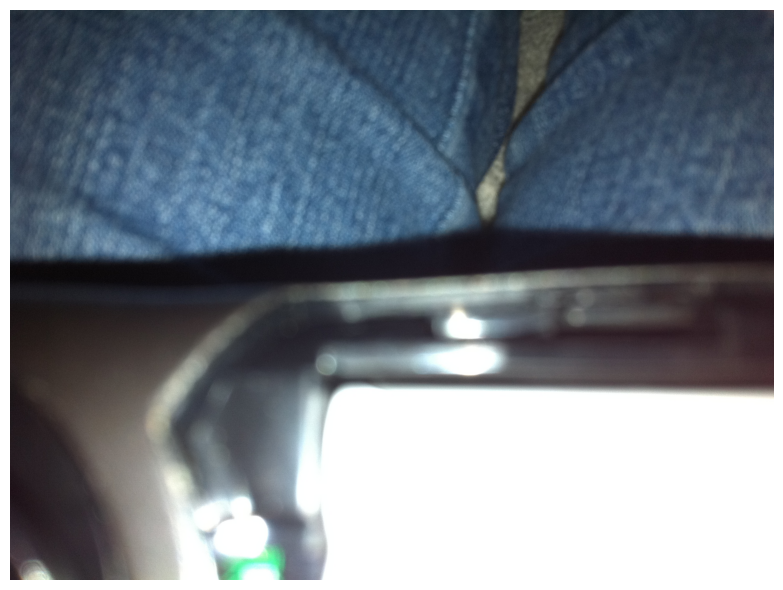

Image: VizWiz_val_00000228.jpg
Question: What's on the screen?
BLIP: toaster
Majority: unanswerable
Human answers: [('unanswerable', 6), ('windows', 2), ('pop up', 1), ('box', 1)]
Answerable: 0
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Failed to abstain


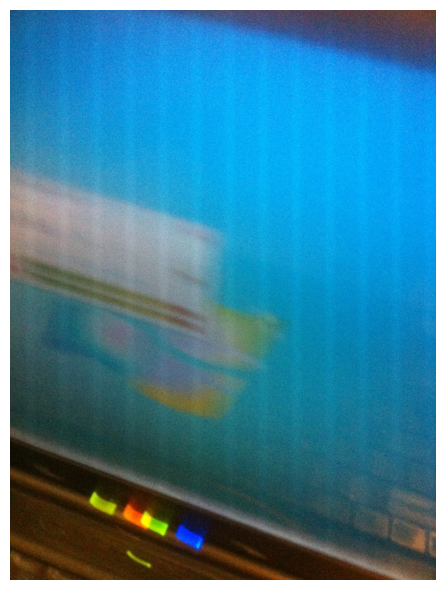

Image: VizWiz_val_00000111.jpg
Question: what is this
BLIP: car
Majority: unanswerable
Human answers: [('unanswerable', 6), ('stroller', 1), ('cars', 1), ('carriage', 1), ('car', 1)]
Answerable: 0
VQA score: 0.3
VQA category: Partial VQA credit
Answerability category: Failed to abstain


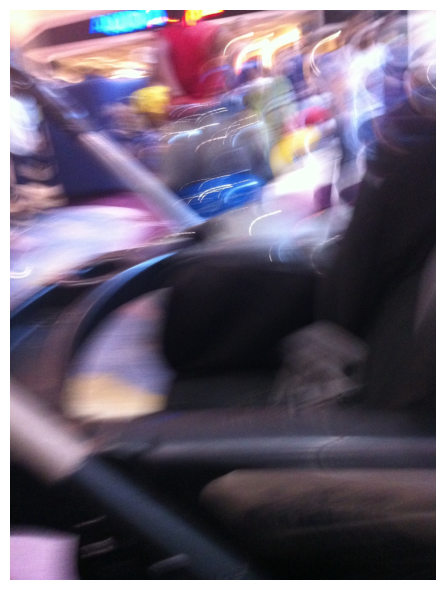

Image: VizWiz_val_00000146.jpg
Question: Hopefully you can see what this screen says.
BLIP: no
Majority: unanswerable
Human answers: [('unanswerable', 5), ('yes', 1), ('ok cancel', 1), ('narrator', 1), ('utility manager box', 1)]
Answerable: 0
VQA score: 0.3
VQA category: Partial VQA credit
Answerability category: Failed to abstain


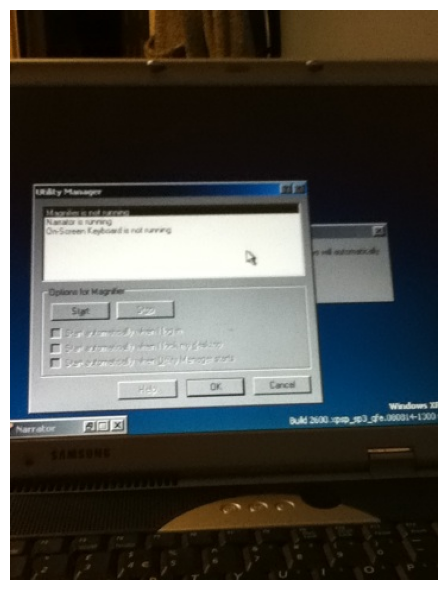

Image: VizWiz_val_00003642.jpg
Question: What are these?
BLIP: lights
Majority: unanswerable
Human answers: [('unanswerable', 8), ('wall', 1), ('flash', 1)]
Answerable: 0
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Failed to abstain


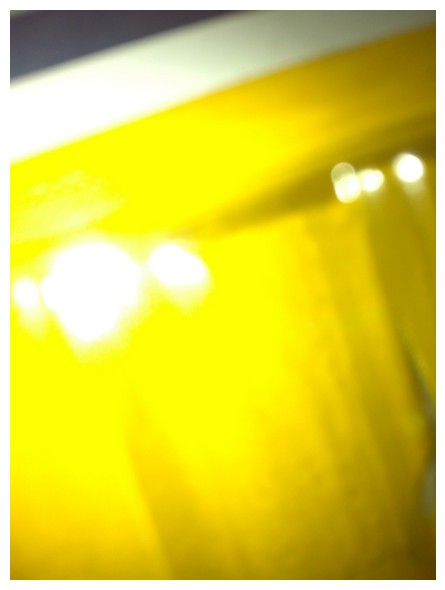

Image: VizWiz_val_00003895.jpg
Question: What is this?
BLIP: can ' t tell
Majority: soup
Human answers: [('soup', 3), ('canned food', 1), ('rich heart chicken pot pie soup', 1), ('preogresso soup', 1), ('can stew', 1)]
Answerable: 1
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Unnecessary abstention


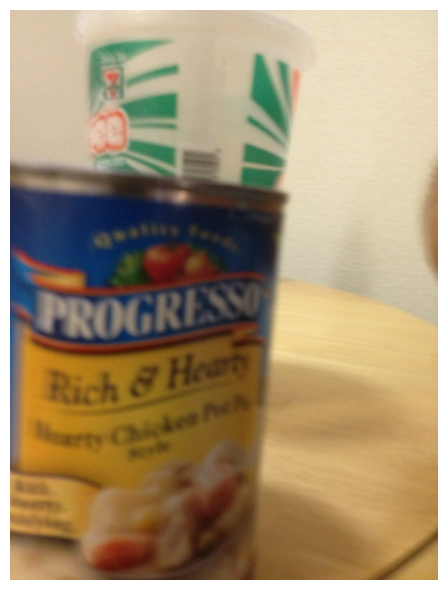

Image: VizWiz_val_00000054.jpg
Question: What's the name of the drink?
BLIP: no idea
Majority: irn bru
Human answers: [('irn bru', 4), ('barr irn bru sugar free', 2), ('irnbru', 1), ('irnbru barr', 1), ('irn barr bru', 1)]
Answerable: 1
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Unnecessary abstention


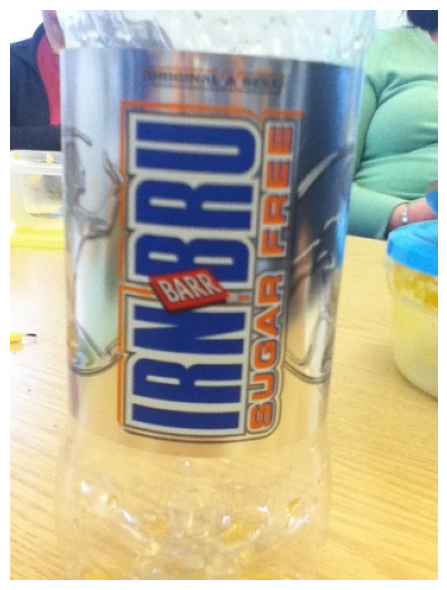

Image: VizWiz_val_00000503.jpg
Question: What letters do I enter in to win the prize?
BLIP: i don ' t know
Majority: jek
Human answers: [('jek', 5), ('unanswerable', 4), ('computer screen', 1)]
Answerable: 1
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Unnecessary abstention


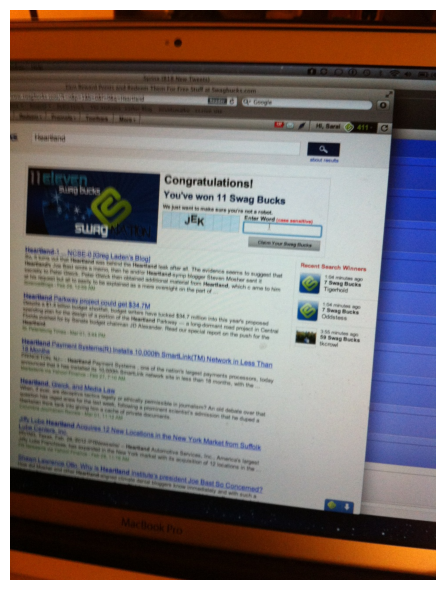

Image: VizWiz_val_00000428.jpg
Question: What does this say?
BLIP: i don ' t know
Majority: welcome to hp recovery manager
Human answers: [('welcome to hp recovery manager', 3), ('hp recovery manager', 3), ('i need immediate help id like to perform maintenance tasks customer service', 1), ('unanswerable', 1), ('hp recovery help screen', 1)]
Answerable: 1
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Unnecessary abstention


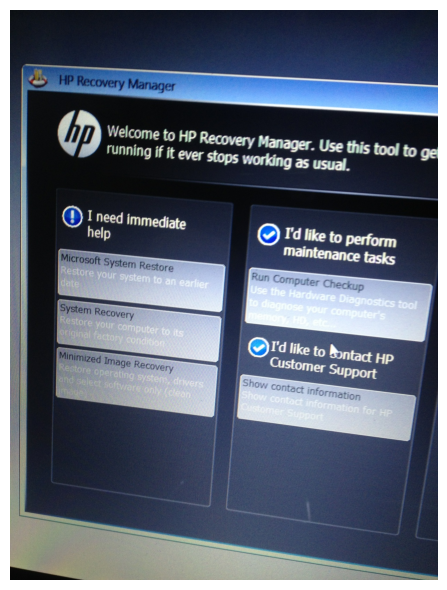

Image: VizWiz_val_00000258.jpg
Question: OK, lets try this again and see if this works. Do you see any kind of an ID number here that would tell me what is what so that I can get disconnected?
BLIP: i don ' t know
Majority: unanswerable
Human answers: [('unanswerable', 4), ('yes', 2), ('no', 2), ('no but youre mouse almost on top stop button', 1), ('no id number present', 1)]
Answerable: 1
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Unnecessary abstention


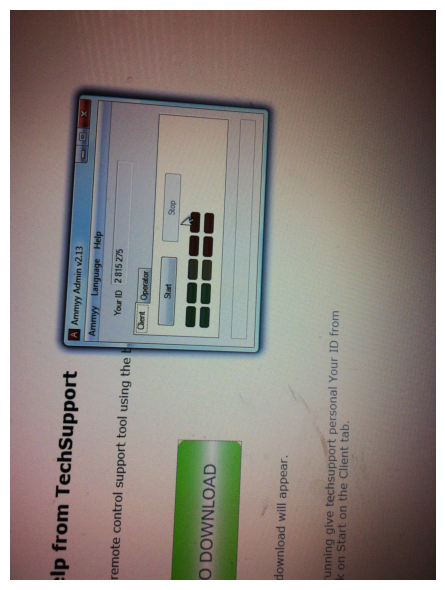

Image: VizWiz_val_00000798.jpg
Question: What does this key say on the paper? Hopefully you guys can see it right. 
BLIP: i don ' t know
Majority: unanswerable
Human answers: [('unanswerable', 7), ('last 3 4 cvvk m6uc fj54', 1), ('dontknow', 1), ('can see part 7 cvvk m6uc fj54 guessing starts 211', 1)]
Answerable: 0
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Correct abstention (heuristic)


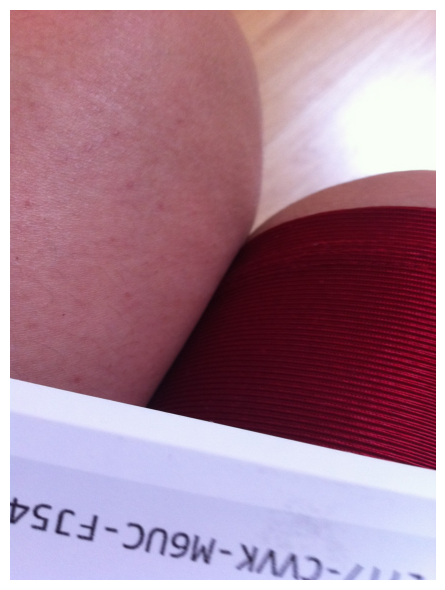

Image: VizWiz_val_00000647.jpg
Question: What does this capthca say?
BLIP: no idea
Majority: unanswerable
Human answers: [('unanswerable', 8), ('cant tell not captcha', 1), ('not legible', 1)]
Answerable: 0
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Correct abstention (heuristic)


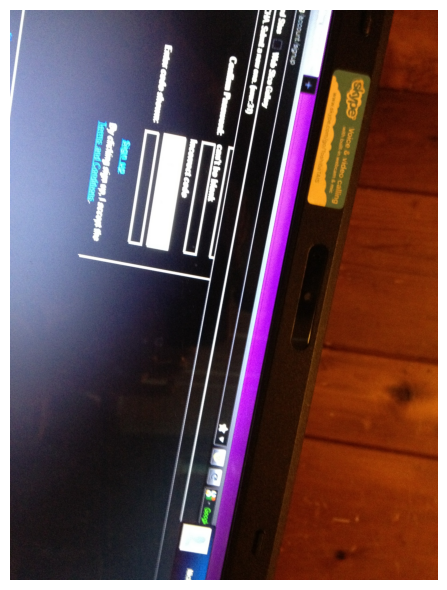

Image: VizWiz_val_00000332.jpg
Question: I'm trying again.  I moved the camera.  Can you tell me where this piece of mail is from?  Thank you.
BLIP: i don ' t know
Majority: unanswerable
Human answers: [('unanswerable', 5), ('vancouver washington', 2), ('no', 1), ('clark', 1), ('first word clark cant read other name', 1)]
Answerable: 0
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Correct abstention (heuristic)


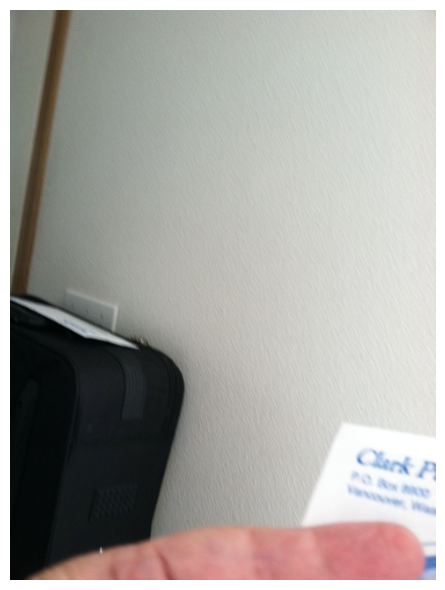

Image: VizWiz_val_00000520.jpg
Question: What does this sign say?
BLIP: no idea
Majority: unanswerable
Human answers: [('unanswerable', 10)]
Answerable: 0
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Correct abstention (heuristic)


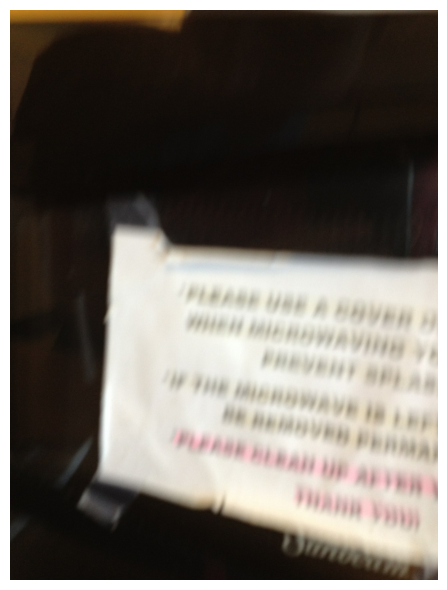

Image: VizWiz_val_00003219.jpg
Question: Okay, what kind of jerky is this again?
BLIP: no idea
Majority: unanswerable
Human answers: [('unanswerable', 6), ('beef', 2), ('jack links', 1), ('ds', 1)]
Answerable: 0
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Correct abstention (heuristic)


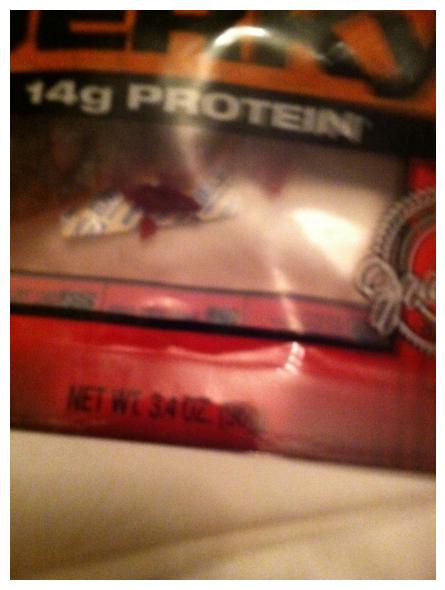

Image: VizWiz_val_00004301.jpg
Question: What is in this can?
BLIP: tea
Majority: green beans
Human answers: [('green beans', 7), ('unanswerable', 2), ('beans', 1)]
Answerable: 1
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Answered answerable question


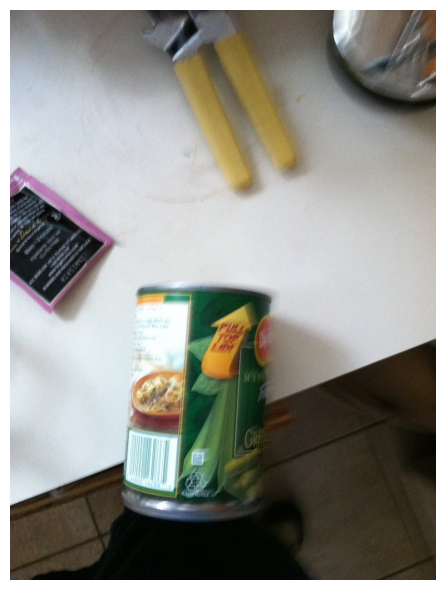

Image: VizWiz_val_00002473.jpg
Question: WHAT IS THIS?
BLIP: sandwich
Majority: crackers
Human answers: [('crackers', 10)]
Answerable: 1
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Answered answerable question


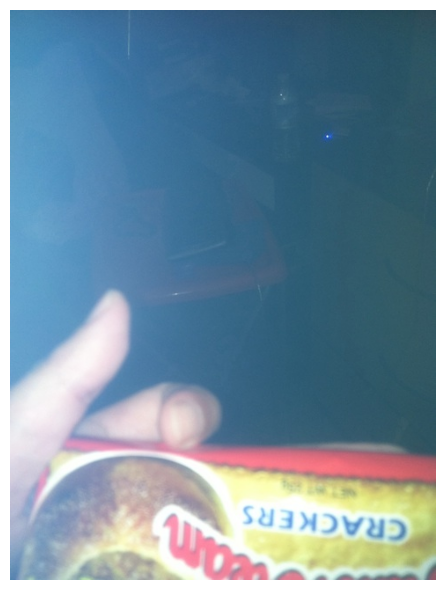

Image: VizWiz_val_00003188.jpg
Question: What is in this can?
BLIP: beer
Majority: unanswerable
Human answers: [('unanswerable', 8), ('beans', 1), ('this image blurry', 1)]
Answerable: 0
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Failed to abstain


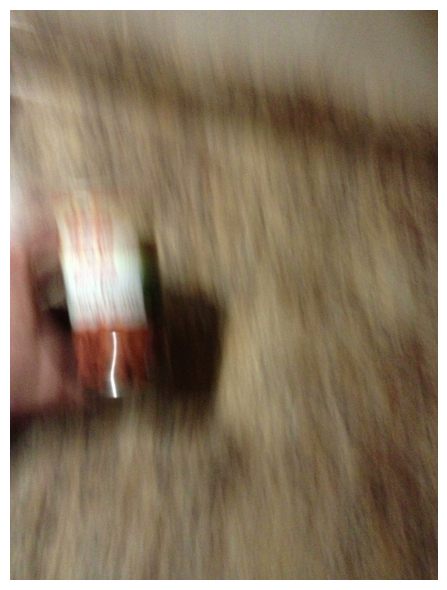

Image: VizWiz_val_00003534.jpg
Question: can you please describe this card to me and its orientation? thank you.
BLIP: yes
Majority: card turned to left says swords image 5 swords
Human answers: [('card turned to left says swords image 5 swords', 1), ('unanswerable', 1), ('swords horizontal', 1), ('horizontal', 1), ('tarot swords card', 1)]
Answerable: 1
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Answered answerable question


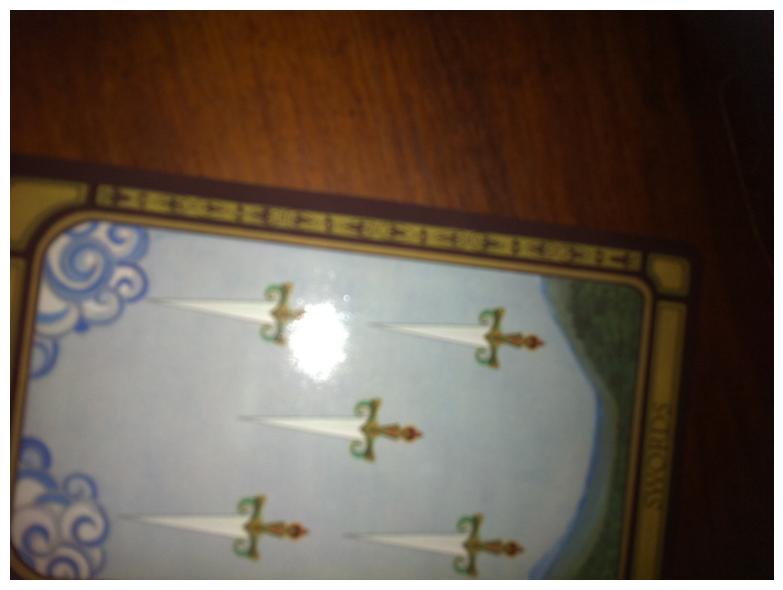

Image: VizWiz_val_00004101.jpg
Question: What's the color?
BLIP: red and white
Majority: unanswerable
Human answers: [('unanswerable', 6), ('red white', 2), ('white', 2)]
Answerable: 0
VQA score: 0.0
VQA category: Zero VQA credit
Answerability category: Failed to abstain


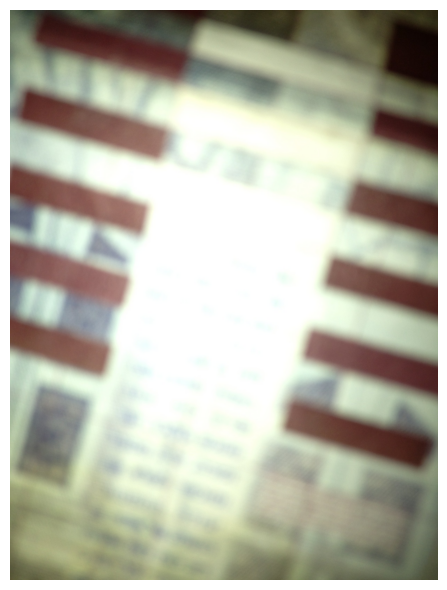

Image: VizWiz_val_00001710.jpg
Question: what is this?
BLIP: bag
Majority: bag
Human answers: [('bag', 2), ('unanswerable', 2), ('yellow plastic bag', 2), ('plastic bag', 2), ('plastic shopping bag', 1)]
Answerable: 1
VQA score: 0.6
VQA category: Partial VQA credit
Answerability category: Answered answerable question


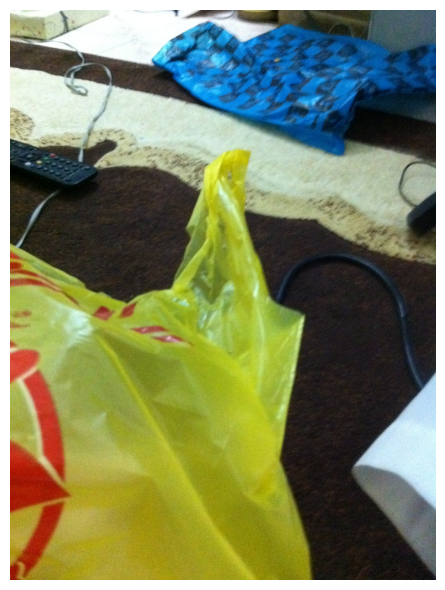

Image: VizWiz_val_00002610.jpg
Question: What color is that? Thank you.
BLIP: white
Majority: grey
Human answers: [('grey', 8), ('white', 1), ('black', 1)]
Answerable: 1
VQA score: 0.3
VQA category: Partial VQA credit
Answerability category: Answered answerable question


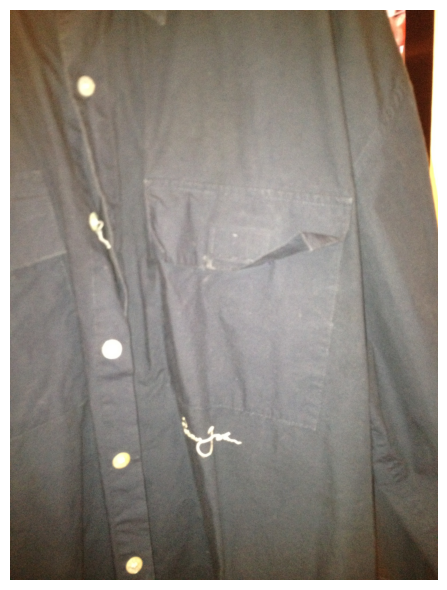

Image: VizWiz_val_00003107.jpg
Question: What is this?
BLIP: medicine bottle
Majority: unanswerable
Human answers: [('unanswerable', 4), ('vitamins', 1), ('plastic bottle', 1), ('supplement', 1), ('medicine bottle', 1)]
Answerable: 1
VQA score: 0.3
VQA category: Partial VQA credit
Answerability category: Answered answerable question


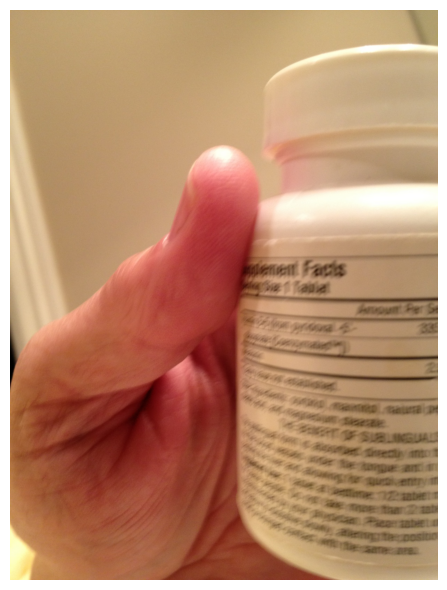

Image: VizWiz_val_00004305.jpg
Question: Can you tell me what this box says?
BLIP: no
Majority: ultimate kitchen miracle
Human answers: [('ultimate kitchen miracle', 4), ('yes', 1), ('all in 1 kitchen miracle', 1), ('food slicer', 1), ('no', 1)]
Answerable: 1
VQA score: 0.3
VQA category: Partial VQA credit
Answerability category: Answered answerable question


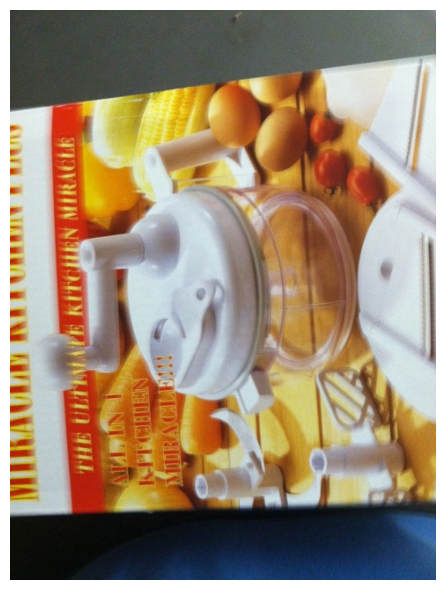

Image: VizWiz_val_00000875.jpg
Question: What is this?
BLIP: computer screen
Majority: monitor
Human answers: [('monitor', 3), ('computer', 2), ('computer screen', 2), ('printer pop up on top survey something', 1), ('prompt screen', 1)]
Answerable: 1
VQA score: 0.6
VQA category: Partial VQA credit
Answerability category: Answered answerable question


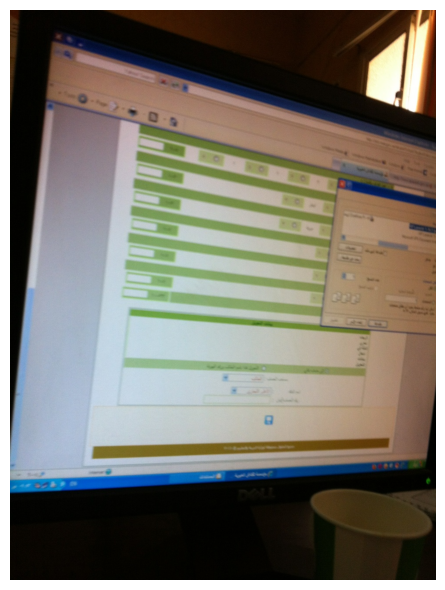

In [29]:

from pathlib import Path
from PIL import Image
from collections import Counter
import matplotlib.pyplot as plt
import textwrap

IMAGE_DIR = BASE / "data" / "val"

def show_error_examples(
    category,
    column="answerability_category",
    n=5,
    seed=42
):
    subset = analysis_df[
        analysis_df[column] == category
    ]

    if subset.empty:
        print(f"No examples found: {category}")
        return

    sample = subset.sample(
        n=min(n, len(subset)),
        random_state=seed
    )

    for _, row in sample.iterrows():
        image_path = IMAGE_DIR / row["image"]

        fig, ax = plt.subplots(figsize=(8, 6))

        if image_path.exists():
            with Image.open(image_path) as img:
                ax.imshow(img.convert("RGB"))
        else:
            ax.text(
                0.5, 0.5, "Image not found",
                ha="center", va="center"
            )

        ax.axis("off")

        human_answers = Counter(
            a["answer"] for a in row["answers"]
        ).most_common(5)

        print("=" * 65)
        print("Image:", row["image"])
        print("Question:", row["question"])
        print("BLIP:", row["prediction"])
        print("Majority:", row["majority_answer"])
        print("Human answers:", human_answers)
        print("Answerable:", row["answerable"])
        print("VQA score:", round(row["vqa_style_score"], 2))
        print("VQA category:", row["vqa_category"])
        print("Answerability category:", row["answerability_category"])

        plt.tight_layout()
        plt.show()


# Answerability analysis
show_error_examples("Failed to abstain")
show_error_examples("Unnecessary abstention")
show_error_examples("Correct abstention (heuristic)")

# VQA correctness analysis
show_error_examples(
    "Zero VQA credit",
    column="vqa_category"
)

show_error_examples(
    "Partial VQA credit",
    column="vqa_category"
)


Save examples for manual analysis

In [30]:

from pathlib import Path
import json

ERROR_DIR = OUTPUT_ROOT / "error_analysis"
ERROR_DIR.mkdir(parents=True, exist_ok=True)

# Save full classifications
analysis_df[
    [
        "image",
        "question",
        "prediction",
        "majority_answer",
        "answerable",
        "vqa_style_score",
        "is_abstention",
        "vqa_category",
        "answerability_category"
    ]
].to_csv(
    ERROR_DIR / "all_error_categories.csv",
    index=False
)

# Save summary distributions
vqa_summary.to_csv(
    ERROR_DIR / "vqa_category_summary.csv",
    index=False
)

answerability_summary.to_csv(
    ERROR_DIR / "answerability_category_summary.csv",
    index=False
)

# Create manual review samples
review_parts = []

for column, categories in {
    "vqa_category": [
        "Zero VQA credit",
        "Partial VQA credit",
        "Full VQA credit"
    ],
    "answerability_category": [
        "Failed to abstain",
        "Unnecessary abstention",
        "Correct abstention (heuristic)"
    ]
}.items():
    for category in categories:
        subset = analysis_df[analysis_df[column] == category]

        if not subset.empty:
            review_parts.append(
                subset.sample(
                    n=min(15, len(subset)),
                    random_state=42
                )
            )

review_df = (
    pd.concat(review_parts, ignore_index=True)
    .drop_duplicates(subset="image")
    .copy()
)

review_df["human_answers"] = review_df["answers"].apply(
    lambda answers: str(
        Counter(a["answer"] for a in answers).most_common(5)
    )
)

review_df["visual_failure_type"] = ""
review_df["observation"] = ""

review_df[
    [
        "image",
        "question",
        "prediction",
        "majority_answer",
        "human_answers",
        "answerable",
        "vqa_style_score",
        "vqa_category",
        "answerability_category",
        "visual_failure_type",
        "observation"
    ]
].to_csv(
    ERROR_DIR / "manual_error_review.csv",
    index=False
)

print("All updated error-analysis files saved to:", ERROR_DIR)
print("Manual review examples:", len(review_df))


All updated error-analysis files saved to: /content/drive/MyDrive/VQA-Project/results/blip_pretrained/error_analysis
Manual review examples: 90


## 3.3 VQA Correctness and Answerability Analysis

To avoid conflating VQA answer correctness with answerability detection, the evaluation was divided into two independent classification systems.

### VQA Correctness Distribution

Predictions were categorized according to the VQA-style scores they received, regardless of question answerability.

| VQA Category | Count | Percentage |
|---|---:|---:|
| Zero VQA credit | 3,153 | 73.00% |
| Partial VQA credit | 615 | 14.24% |
| Full VQA credit | 551 | 12.76% |
| **Total** | **4,319** | **100%** |

**Observations:**

- 73.00% of predictions received zero credit under the implemented VQA-style metric.
- 14.24% received partial credit, indicating some agreement with human annotations.
- 12.76% achieved full agreement according to the metric.
- These results demonstrate the limitations of pretrained BLIP on VizWiz without dataset-specific fine-tuning.

The distribution of zero, partial, and full credit differs from overall VQA-style accuracy (19.94%) because the overall score averages individual prediction scores, including partial-credit values.

### Answerability Detection Distribution

Answerability detection was evaluated separately using the ground-truth `answerable` label and a heuristic list of natural-language uncertainty expressions.

| Answerability Category | Count | Percentage |
|---|---:|---:|
| Answered answerable question | 2,846 | 65.89% |
| Failed to abstain | 1,254 | 29.03% |
| Recognized uncertainty (heuristic) | 131 | 3.03% |
| Unnecessary abstention | 88 | 2.04% |
| **Total** | **4,319** | **100%** |

**Observations:**

- BLIP provided a non-abstaining response to 2,846 answerable questions. This does not necessarily mean the answer was correct.
- The model failed to express recognizable uncertainty for 1,254 questions labelled unanswerable.
- BLIP expressed uncertainty for 131 unanswerable questions.
- The model unnecessarily abstained on 88 questions labelled answerable.

**Important distinction:** A failure to abstain does not necessarily imply zero VQA credit. For example, BLIP answered `no` to a question labelled unanswerable, but three human annotators also answered `no`, resulting in a VQA-style score of 0.90.

Therefore, VQA correctness and answerability detection should be interpreted as related but distinct evaluation dimensions.

---

## 5. Qualitative Error Analysis

Representative examples were inspected to identify possible causes of poor performance. The analysis considered prediction correctness, answerability, image quality, and agreement among human annotations.

### 5.1 Poor Image Quality and Unsupported Predictions

Several images contained severe blur, overexposure, or poor framing.

| Example | BLIP Prediction | Observation |
|---|---|---|
| Blurry computer screen | toaster | Prediction unsupported by the visible screen |
| Heavily blurred scene | car | Specific object predicted despite substantial visual ambiguity |
| Overexposed yellow image | lights | Image provides insufficient detail to reliably identify the requested objects |

These examples suggest that BLIP sometimes produces specific answers when the available visual information is insufficient.

### 5.2 Text Recognition Difficulties

Some errors involved text visible in the image.

| Question | BLIP Prediction | Human Reference | Observation |
|---|---|---|---|
| What words are in the image? | three legged mare | cabinet | Incorrect recognition of visible writing |
| What flavor jam is this? | raspberry | marionberry | Incorrect extraction of product-specific text |
| What does this say? | i don't know | HP Recovery Manager text | Failure to answer a text-reading question |
| What's the name of the drink? | no idea | IRN-BRU | Failure to recognize readable product branding |

These examples suggest that fine-grained text recognition is a potential weakness of pretrained BLIP.

### 5.3 Incorrect Fine-Grained Object Recognition

BLIP occasionally recognized the general category of an object but generated an incorrect specific answer.

Examples included:

- Predicting `raspberry` instead of `marionberry` for a jam label.
- Predicting `oatmeal with raisins` instead of `granola bars`.
- Giving incomplete or inconsistent colour descriptions.

These errors suggest limitations in detailed visual discrimination and product identification.

### 5.4 Partial Agreement and Annotation Ambiguity

Some predictions were plausible but did not fully match the human reference answers.

For example:

- BLIP predicted `alligator` for a shirt showing the Florida Gators logo.
- Human annotators provided more detailed answers including `crocodile no words` and `florida gators logo`.

The model received partial credit because its answer overlapped with some, but not all, human responses.

This illustrates the importance of considering annotation diversity when interpreting VQA evaluation scores.

### 5.5 Answerability Versus VQA Correctness

A VizWiz example asked whether a cordless-phone battery's model and name could be seen.

- Ground-truth answerability: `0`
- BLIP prediction: `no`
- Human answers: 7 × `unanswerable`, 3 × `no`
- VQA-style score: `0.90`

The prediction was categorized as a failure to abstain because BLIP did not use a recognized uncertainty expression. However, the prediction received substantial VQA credit due to agreement with three human annotators.

This example demonstrates that answerability detection and VQA correctness must be evaluated independently.

---

## 6. Key Findings

1. **Low overall VQA performance:** Pretrained BLIP achieved 19.94% VQA-style accuracy across the complete VizWiz validation set.

2. **High proportion of zero-credit predictions:** 73.00% of predictions received no VQA credit.

3. **Weak answerability detection:** The model identified only 131 of 1,385 unanswerable examples using the heuristic abstention detector, resulting in 9.46% recall.

4. **Visual grounding difficulties:** Image inspection revealed predictions unsupported by severely blurred, overexposed, or poorly framed images.

5. **Text-reading limitations:** Several failures involved recognition of printed text, product labels, and computer-screen content.

6. **Annotation diversity:** Some partially correct predictions differed from human responses in specificity or wording.

These findings motivate comparison with a question-only baseline and subsequent VizWiz-specific fine-tuning.

---

## 7. Limitations

- VQA-style accuracy uses simple answer normalization and has not yet been verified with the official VizWiz evaluator.
- Answerability detection relies on a manually defined uncertainty phrase list.
- A non-abstaining prediction is not necessarily incorrect under the VQA scoring metric.
- Some predictions may be semantically reasonable despite low exact-answer agreement.
- The initial image inspection is qualitative and does not establish the statistical prevalence of individual visual failure types.
- A manual-review sample has been exported, but its visual failure labels and observations have not yet been completed.
- The pretrained BLIP results have not yet been compared with the question-only baseline using a consolidated evaluation procedure.

---

## 8. Next Steps

### Step 1 — Question-Only vs. BLIP Comparison

**Status:** Next

- Retrieve predictions from the TF-IDF question-only baseline.
- Verify that both models were evaluated on the same 4,319 validation examples.
- Apply identical answer normalization and VQA-style scoring.
- Compare overall, answerable, and unanswerable accuracy.
- Analyze examples where the two models disagree.

**Deliverable:** Baseline comparison table, visualizations, and interpretation.

### Step 2 — Official VizWiz Evaluation

**Status:** Pending

- Verify benchmark performance with the official VizWiz/VQA evaluation implementation.
- Report official accuracy separately from preliminary VQA-style metrics.

### Step 3 — Complete Manual Error Annotation

**Status:** Partially complete

- Review representative examples.
- Assign visual failure types.
- Document observations supported by image evidence.

### Step 4 — Fine-Tune BLIP on VizWiz

**Status:** Not started

- Prepare training data and target answers.
- Fine-tune BLIP on the VizWiz training split.
- Evaluate answer generation and answerability detection.
- Compare fine-tuned BLIP with both pretrained baselines.

### Step 5 — Final Evaluation and Report

**Status:** Pending

- Consolidate results across all models.
- Examine the contribution of image information.
- Discuss failure cases, strengths, limitations, and possible improvements.